In [21]:
# Import important Libraries
import kagglehub
import pandas as pd
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Advanced Visualization
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
pio.renderers.default = "colab"   # Forces native colab rendering

# Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score)

# Interpretability
import shap

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

# Donloads the dataset and returns the local folder path
path = kagglehub.dataset_download("fedesoriano/company-bankruptcy-prediction")

print ("Path to dataset files:", path)
print("Files in folder:", os.listdir(path))

df = pd.read_csv(os.path.join(path, "data.csv"))

print(f"Loaded {df.shape[0]} rows and {df.shape[1]} columns")
df.head()

Using Colab cache for faster access to the 'company-bankruptcy-prediction' dataset.
Path to dataset files: /kaggle/input/company-bankruptcy-prediction
Files in folder: ['data.csv']
Loaded 6819 rows and 96 columns


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


In [22]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Advanced Visualization
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
pio.renderers.default = "colab"   # Forces native colab rendering

# Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score)

# Interpretability
import shap

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

In [23]:
# Data Cleaning

#  1. Clean Column Names
target_col = 'Bankrupt?'
feature_cols = [col for col in df.columns if col != target_col]
col_mapping = {col: f'X{i+1}' for i, col in enumerate(feature_cols)}
col_mapping[target_col] = 'Target'
df = df.rename(columns=col_mapping)

# 3. Check for Missing Values and Duplicates
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

# Drop duplicates if any
df = df.drop_duplicates()

# 4. Check the Target Distribution (Class Imbalance)
print("\nTarget Distribution:")
print(df['Target'].value_counts(normalize=True) * 100)

Missing Values: 0
Duplicate Rows: 0

Target Distribution:
Target
0    96.77372
1     3.22628
Name: proportion, dtype: float64


In [24]:
fig = px.pie(
    df['Target'].value_counts().reset_index(),
    values='count', names='Target',
    hole=0.5, title='Healthy (0) vs Bankrupt (1) Companies',
    color='Target', color_discrete_map={0: '#636EFA', 1: '#EF553B'}
)
fig.update_traces(textposition='inside', textinfo='percent+label')
fig.show()

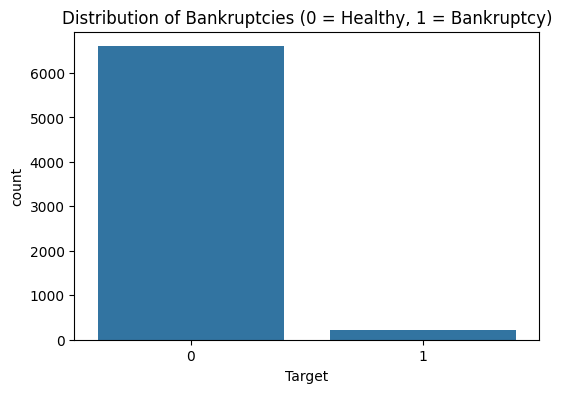

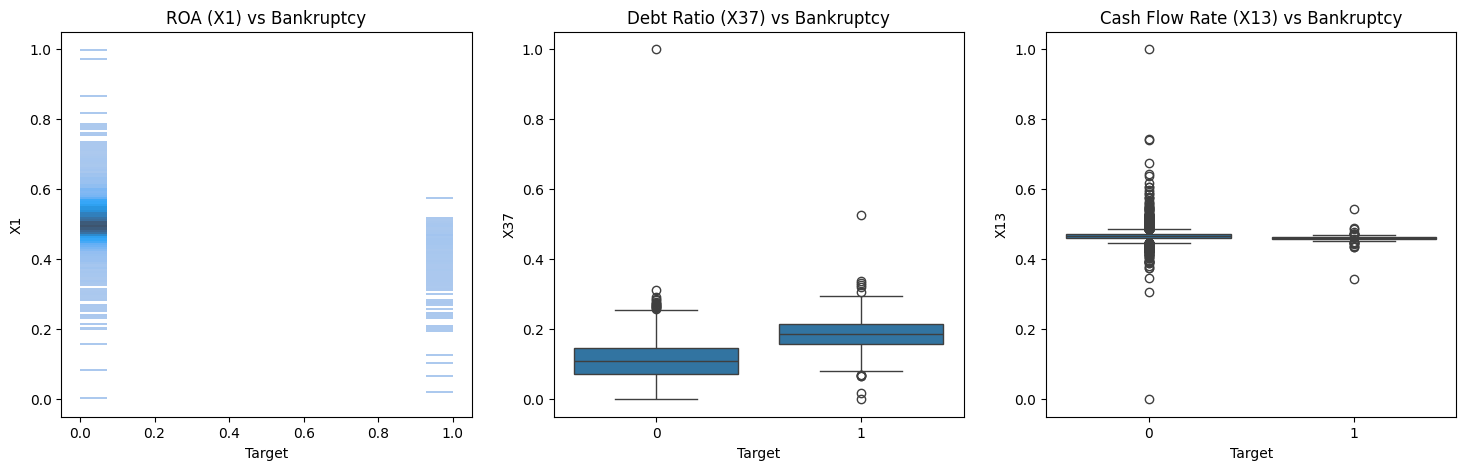

In [25]:
# Exploratory Data Analysis (EDA)

# 1. Visualize the Target Imbalance
plt.figure(figsize=(6,4))
sns.countplot(x='Target', data=df)
plt.title('Distribution of Bankruptcies (0 = Healthy, 1 = Bankruptcy)')
plt.show()

# 2. Visualize Key Financial Ratios vs Bankruptcy
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ROA (x1)
sns.histplot(x='Target', y='X1', data=df, ax=axes[0])
axes[0].set_title('ROA (X1) vs Bankruptcy')

# Debt Ratio (X37)
sns.boxplot(x='Target', y='X37', data=df, ax=axes[1])
axes[1].set_title('Debt Ratio (X37) vs Bankruptcy')

# Cash Flow Rate (X13)
sns.boxplot(x='Target', y='X13', data=df, ax=axes[2])
axes[2].set_title('Cash Flow Rate (X13) vs Bankruptcy')

plt.show()


### 1. ROA (X1) vs Bankruptcy (Left Plot)
Observation: The "0" (Healthy) group has a very tight box near 0.0, with some outliers going up to 1.0. The "1" (Bankrupt) group is almost entirely concentrated at 0.0.

Interpretation: This is a strong signal. Return on Assets (ROA) is a measure of profitability. Healthy companies generally have positive ROA. Bankrupt companies almost universally have an ROA of 0 (or negative, which might be represented as 0 in this scaled dataset). This confirms that profitability is a massive indicator of survival.

Note: The long tail of blue dots on the left is interesting. Those are healthy companies with very high ROA. They are outliers in the healthy class, but their presence makes the "0" box look large. However, the key takeaway is the clear separation at the bottom: if ROA is 0, the risk is much higher.

### 2. Debt Ratio (X37) vs Bankruptcy (Middle Plot)
Observation: The "0" (Healthy) group has a lower median debt ratio (around 0.1). The "1" (Bankrupt) group has a higher median (around 0.2) and the box (the middle 50% of data) is shifted higher.

Interpretation: This is another classic signal. Higher leverage (debt) increases the risk of bankruptcy. Bankrupt companies carry a heavier debt burden. While there is overlap between the two boxes (meaning some healthy companies have high debt, and some bankrupt companies have low debt), the trend is clear: the bankrupt group is shifted towards higher debt levels.

### 3. Cash Flow Rate (X13) vs Bankruptcy (Right Plot)
Observation: This is the most interesting plot. The medians (the horizontal line inside the box) for both Healthy and Bankrupt are almost identical (around 0.45). The boxes are very similar in size.

Interpretation: On its own, Cash Flow Rate (X13) might not be a strong predictor in this dataset. Both groups look very similar. However, the outliers (the circles); the Healthy group has a lot of outliers extending up to 1.0 (and one at 0.0). The Bankrupt group has fewer outliers. This suggests that while cash flow is important, extreme cash flow values might be a characteristic of healthy companies. But this feature alone won't separate the classes well.